# Lecture 22, Weather types and temporal downscaling

> Two ways to bring a coarse model closer to the weather that a catchment feels

Lecture 16 set out the downscaling problem and Lecture 21 introduced weather generators. This lecture adds two ideas that fit together:

- **Part A, weather types.** Instead of regressing rainfall on pressure at every grid point, we sort the days into a handful of recurring circulation patterns and ask how much it rains on each type.
- **Part B, temporal downscaling.** Climate models and many gridded products give *daily* rainfall, yet urban drains and small catchments respond to *hourly* intensity. We split a daily total into hourly values by borrowing the hourly pattern of a similar observed day (k-nearest-neighbour resampling).

By the end of this lecture you should be able to:

- explain what a weather type is and the difference between a subjective and an objective classification,
- derive principal component analysis (PCA) as an eigenvalue problem and k-means as two alternating steps that lower the within-cluster variance,
- generate daily rainfall conditioned on a weather-type sequence (a Markov chain on the types), and say how the future is built from it and what it cannot do,
- derive the k-nearest-neighbour (kNN) resampling algorithm, including the $1/j$ kernel, and apply it to disaggregate daily rainfall into hourly values,
- prove that proportional adjustment keeps the daily total, and judge a disaggregation with hourly extremes, wet-hour fraction, autocorrelation and annual maxima by duration.

**All data in this lecture are synthetic.** They were generated for teaching and are not observations. Each data section says how to swap in real data. A companion Excel workbook, `data/downscaling/lec22/lec22_worked_examples.xlsx`, repeats a small k-means example and one kNN disaggregation with live formulas; the code cells print the same numbers.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.optimize import linear_sum_assignment
from scipy.stats import beta as beta_dist

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def read_data(name):
    # read a file of the lecture-22 data folder; fall back to GitHub if the repository is not present (Colab)
    path = "data/downscaling/lec22/" + name
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return pd.read_csv("https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/" + path)

# PART A. Weather types

# 1) The idea: a few circulation patterns, many days

Rain at a site does not depend on one number. It depends on where the monsoon trough lies, whether a low-pressure system has moved in from the Bay of Bengal, whether a western disturbance is crossing north-west India. Yet the *circulation* on any day is usually close to one of a small number of recurring patterns. Some examples for India:

| Pattern (a "weather type") | Typical circulation | Rainfall consequence |
|:--|:--|:--|
| **Active monsoon** | Monsoon trough near its normal position over central India, strong westerlies over the peninsula | Widespread, heavy rain over central and western India |
| **Break monsoon** | Trough shifted north to the Himalayan foothills, weak flow over the peninsula | Dry over most of India, heavy rain on the Himalayan foothills and north-east |
| **Western disturbance** | Upper-air trough moving from west to east over north-west India (mainly winter and spring) | Rain and mountain snow in the north-west |
| **Weak or anticyclonic** | No organised system, high pressure | Mostly dry |

The idea of **weather-type downscaling** is to (1) classify every day into one of these types using large-scale circulation, which a climate model simulates reasonably well, and (2) describe local rainfall *given the type*. The model then supplies the type sequence, and the rainfall statistics supply the local detail. A single grid-point regression cannot represent "the trough is in the wrong place" so easily; the type does.

### Subjective and objective classification

- **Empirical (subjective) classification.** An expert looks at weather maps and assigns each day to a named type. The best known example is the Lamb weather types for the British Isles (anticyclonic, cyclonic, westerly, northerly, and so on). It encodes decades of experience, but it is laborious and cannot be repeated on climate-model output by anyone else.
- **Objective classification by rules.** A formula computes flow direction, flow strength and vorticity from sea-level pressure at a few points, and fixed thresholds then name the type. The Jenkinson and Collison scheme does this for the Lamb types. It is reproducible and can be applied to model output.
- **Objective classification by clustering.** No names are given in advance. A clustering algorithm groups days whose circulation fields resemble one another, and we name the groups afterwards by looking at their average map. This is the route taken here, because it works for any region.

Clustering needs three ingredients: a *field* for each day (for example sea-level pressure or 850 hPa wind on a grid), a *distance* between two days, and an *algorithm* that minimises the spread inside the groups. Sections 2 and 3 derive the first reduction step (PCA) and the algorithm (k-means).

# 2) Reducing the field: PCA as an eigenproblem

A daily pressure field on a grid with $p$ points is a vector in $p$ dimensions, and neighbouring points are strongly correlated. We replace it by a few numbers that keep most of the variability.

Let $Z$ be the $n \times p$ matrix of $n$ days, each column (grid point) standardised to zero mean and unit variance. The sample covariance matrix is

$$S = \frac{1}{n-1} Z^{\mathsf T} Z \qquad (p \times p,\ \text{symmetric}).$$

**Find the direction $w$ (a unit vector, $w^{\mathsf T} w = 1$) along which the days vary most.** The score of day $i$ on $w$ is $s_i = z_i^{\mathsf T} w$, and the variance of the scores is

$$\mathrm{Var}(s) = \frac{1}{n-1}\sum_i (z_i^{\mathsf T} w)^2 = w^{\mathsf T} S\, w .$$

Maximise $w^{\mathsf T} S w$ subject to $w^{\mathsf T} w = 1$ with a Lagrange multiplier $\lambda$:

$$\mathcal{L} = w^{\mathsf T} S w - \lambda\,(w^{\mathsf T} w - 1), \qquad \frac{\partial \mathcal{L}}{\partial w} = 2 S w - 2\lambda w = 0 \;\;\Longrightarrow\;\; \boxed{S\,w = \lambda\, w}.$$

So $w$ must be an **eigenvector** of $S$, and multiplying by $w^{\mathsf T}$ gives the variance along it: $w^{\mathsf T} S w = \lambda\, w^{\mathsf T} w = \lambda$. The direction of largest variance is therefore the eigenvector with the **largest eigenvalue**. Because $S$ is symmetric, its eigenvectors are orthogonal, so the second principal component (the best direction orthogonal to the first) is the eigenvector with the second largest eigenvalue, and so on.

Two consequences:

- The fraction of total variance carried by principal component $m$ is $\lambda_m / \sum_l \lambda_l$. For standardised data the denominator is the trace of $S$, which equals $p$ because every variance is 1.
- Using *all* eigenvectors is only a rotation, so Euclidean distances between days are unchanged. Keeping the first $M$ components (enough for about 85 to 90 % of the variance) discards mostly grid-point noise and makes the clustering cheaper and more stable.

For fields on a latitude-longitude grid one multiplies each grid point by $\sqrt{\cos\varphi}$ so that high latitudes, where cells are smaller, do not count too much.

### Synthetic circulation data

Real input would be, for example, ERA5 sea-level pressure anomalies over South Asia (Lecture 15 shows how to open such a file with xarray). Here we build our own: a 7 by 9 grid (5&ndash;35&deg;N, 65&ndash;105&deg;E), four underlying patterns whose structure imitates the table above, a Markov chain that decides which pattern occurs on each day, a random strength for each day, and spatially smooth noise. A catchment-average rainfall series is drawn from the true type. The code never uses the true types to build the classification; they are kept only to check it.

To use real data, replace `X` by a days-by-grid-points array of pressure anomalies and `rain` by your gauge series on the same days.

In [3]:
rng = np.random.default_rng(22)
lat = np.arange(5, 40, 5); lon = np.arange(65, 110, 5)
LON, LAT = np.meshgrid(lon, lat)
ny_g, nx_g = LAT.shape

def blob(lat0, lon0, amp, sy=6.0, sx=8.0):
    return amp * np.exp(-0.5 * (((LAT - lat0) / sy) ** 2 + ((LON - lon0) / sx) ** 2))

type_names = ["A active", "B break", "C NW disturbance", "D weak"]
patterns = np.stack([
    blob(22, 82, -5.0) + blob(32, 82, 2.0),             # trough over central India
    blob(30, 82, -4.0) + blob(14, 78, 3.0),             # trough moved north, high over the peninsula
    blob(32, 72, -5.0, 5.0, 7.0) + blob(20, 92, 2.0),   # trough over the north-west
    blob(20, 82, 2.5, 10.0, 14.0),                      # broad weak high
])                                                      # hPa anomalies, shape (4, 7, 9)

P_true = np.array([[0.70, 0.10, 0.05, 0.15],            # P[k, l] = Pr(next type l | today k)
                   [0.10, 0.70, 0.05, 0.15],
                   [0.05, 0.10, 0.60, 0.25],
                   [0.15, 0.20, 0.15, 0.50]])
p_wet_true = np.array([0.80, 0.25, 0.40, 0.08])
mean_true = np.array([12.0, 3.5, 6.0, 2.0])             # mean wet-day rain [mm]
shape_true = 0.8                                        # gamma shape

n_days = 20 * 365
t_true = np.empty(n_days, int); t_true[0] = 0
for t in range(1, n_days):
    t_true[t] = rng.choice(4, p=P_true[t_true[t - 1]])
strength = rng.lognormal(0.0, 0.25, n_days)
noise = np.stack([gaussian_filter(rng.standard_normal((ny_g, nx_g)), 1.0) for _ in range(n_days)])
noise *= 1.5 / noise.std()                              # noise standard deviation 1.5 hPa
field = strength[:, None, None] * patterns[t_true] + noise
X = field.reshape(n_days, -1)                           # days x grid points [hPa]

wet = rng.random(n_days) < p_wet_true[t_true]
rain = np.where(wet, rng.gamma(shape_true, mean_true[t_true] / shape_true), 0.0)   # mm/day
print(f"{n_days} days, {X.shape[1]} grid points; mean rain {rain.mean():.2f} mm/day, wet-day fraction {(rain > 0).mean():.2f}")

7300 days, 63 grid points; mean rain 3.33 mm/day, wet-day fraction 0.39


In [4]:
# PCA by hand: standardise, covariance matrix, eigen-decomposition
Z = (X - X.mean(0)) / X.std(0, ddof=1)
S = Z.T @ Z / (Z.shape[0] - 1)
lam, W = np.linalg.eigh(S)                              # eigenvalues in ascending order
lam, W = lam[::-1], W[:, ::-1]                          # largest first
explained = lam / lam.sum()
scores = Z @ W                                          # PC scores, days x components

# sanity checks of the derivation
print("trace of S (= number of grid points):", round(np.trace(S), 3), " sum of eigenvalues:", round(lam.sum(), 3))
print("variance of PC1 scores:", round(scores[:, 0].var(ddof=1), 4), " largest eigenvalue:", round(lam[0], 4))
print("PC1 and PC2 uncorrelated:", round(np.corrcoef(scores[:, 0], scores[:, 1])[0, 1], 6))
M = int(np.searchsorted(np.cumsum(explained), 0.85) + 1)
print(f"{M} components explain {100 * explained[:M].sum():.1f} % of the variance")
Y = scores[:, :M]                                       # reduced data used for clustering

trace of S (= number of grid points): 63.0  sum of eigenvalues: 63.0
variance of PC1 scores: 15.6088  largest eigenvalue: 15.6088
PC1 and PC2 uncorrelated: -0.0
10 components explain 86.6 % of the variance


# 3) Clustering the days: k-means

We have $n$ points $x_i$ (the PC scores of the days) in $M$ dimensions and want $K$ groups. Let group $C_k$ have centre (centroid) $\mu_k$. The natural measure of how well the groups describe the data is the **within-cluster sum of squares**

$$J = \sum_{k=1}^{K}\sum_{i \in C_k} \lVert x_i - \mu_k \rVert^{2}.$$

We want the assignment of points to groups and the centroids that minimise $J$. Trying every partition is impossible, but $J$ can be minimised one set of unknowns at a time.

**Step 1, assign.** Fix the centroids. Each point contributes its own term, so $J$ is smallest when every point joins the group whose centroid is nearest:
$$c(i) = \arg\min_k \lVert x_i - \mu_k \rVert^{2}.$$

**Step 2, update.** Fix the assignment and differentiate $J$ with respect to one centroid:
$$\frac{\partial J}{\partial \mu_k} = -2\sum_{i\in C_k}(x_i - \mu_k) = 0 \;\;\Longrightarrow\;\; \mu_k = \frac{1}{n_k}\sum_{i \in C_k} x_i .$$
The second derivative is $2 n_k > 0$, so this is a minimum: the best centre of a group is its **mean**, which gives the method its name.

Repeat the two steps. Neither step can increase $J$, $J \ge 0$, and there are only finitely many ways to partition the points, so the iteration stops after a finite number of steps. It stops at a *local* minimum that depends on the starting centroids, so one runs several random starts and keeps the lowest $J$.

**What does $J$ mean?** Let $\bar x$ be the overall mean and add and subtract $\mu_k$ inside the total sum of squares. The cross term vanishes because $\sum_{i\in C_k}(x_i - \mu_k) = 0$, leaving

$$\underbrace{\sum_i \lVert x_i - \bar x\rVert^{2}}_{\text{total (fixed)}} = \underbrace{\sum_k\sum_{i\in C_k}\lVert x_i - \mu_k\rVert^{2}}_{J = \text{within}} + \underbrace{\sum_k n_k \lVert \mu_k - \bar x\rVert^{2}}_{\text{between}} .$$

The total is fixed, so minimising the within-cluster spread is the same as maximising the spread *between* the cluster centres.

**Choosing $K$.** $J$ always falls as $K$ grows (at $K=n$ it is zero), so we cannot simply minimise it. Look for an "elbow" in $J$ against $K$, check that the types have enough days and make physical sense, and remember that every extra type adds a row to the transition matrix below ($K^2$ numbers). Real data rarely show a sharp elbow; the choice is a judgement.

The spreadsheet `KMeans` sheet works through four iterations on 12 points; the cell after the next code cell reproduces its numbers.

J along the iterations of the best K = 4 run: [542481. 254554. 242362. 241416. 241285. 241271. 241266. 241264. 241263.
 241263. 241262. 241262. 241262. 241262.]
J never increases: True
total 398037 = within 241262 + between 156775  (sum 398037)
J/total for K = 1..8: [1.    0.804 0.676 0.606 0.581 0.56  0.54  0.527] (the bend near K = 4 is gentle; here we know the true number of types is 4)


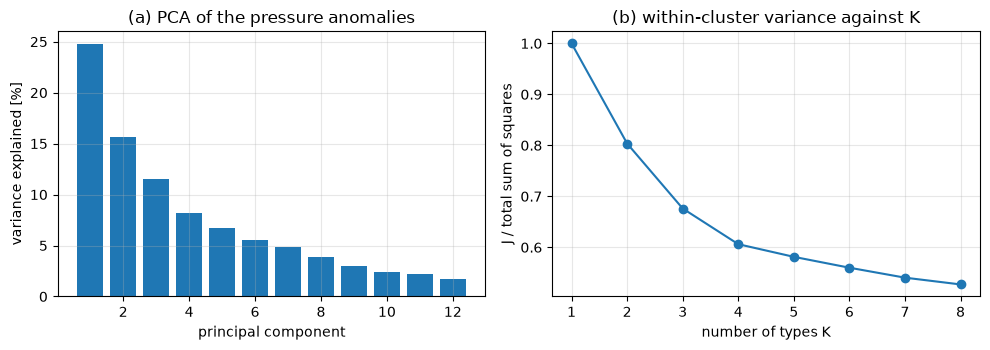

In [5]:
def kmeans(Y, K, n_init=10, max_iter=100, rng=None):
    # k-means with random restarts; returns labels, centroids, J and the history of J of the best run
    rng = rng or np.random.default_rng(0)
    best = None
    for _ in range(n_init):
        C = Y[rng.choice(len(Y), K, replace=False)].copy()
        hist = []
        for it in range(max_iter):
            d2 = ((Y[:, None, :] - C[None]) ** 2).sum(2)           # squared distance to every centroid
            lab = d2.argmin(1)                                       # step 1: assign
            hist.append(d2[np.arange(len(Y)), lab].sum())
            Cn = np.array([Y[lab == k].mean(0) if np.any(lab == k) else C[k] for k in range(K)])   # step 2: update
            if np.allclose(Cn, C): break
            C = Cn
        if best is None or hist[-1] < best[2]:
            best = (lab, C, hist[-1], hist)
    return best

rk = np.random.default_rng(5)
Jk = {}
for K in range(1, 9):
    Jk[K] = kmeans(Y, K, rng=rk)[2]
lab, cent, Jbest, hist = kmeans(Y, 4, rng=rk)
print("J along the iterations of the best K = 4 run:", np.round(hist, 0))
print("J never increases:", bool(np.all(np.diff(hist) <= 1e-9)))
tot = ((Y - Y.mean(0)) ** 2).sum()
between = sum((lab == k).sum() * ((cent[k] - Y.mean(0)) ** 2).sum() for k in range(4))
print(f"total {tot:.0f} = within {Jbest:.0f} + between {between:.0f}  (sum {Jbest + between:.0f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(np.arange(1, 13), 100 * explained[:12]); ax[0].set_xlabel("principal component")
ax[0].set_ylabel("variance explained [%]"); ax[0].set_title("(a) PCA of the pressure anomalies")
ax[1].plot(list(Jk), np.array(list(Jk.values())) / tot, "o-"); ax[1].set_xlabel("number of types K")
ax[1].set_ylabel("J / total sum of squares"); ax[1].set_title("(b) within-cluster variance against K")
fig.tight_layout()
print("J/total for K = 1..8:", np.round([Jk[K_] / tot for K_ in range(1, 9)], 3), "(the bend near K = 4 is gentle; here we know the true number of types is 4)")

cluster           A active  B break  C NW disturbance  D weak
true type                                                    
A active              1979       30                30      27
B break                 41     1935               230      82
C NW disturbance        17       73              1029      46
D weak                  28       66                82    1605


days placed in the matching cluster: 89.7 %


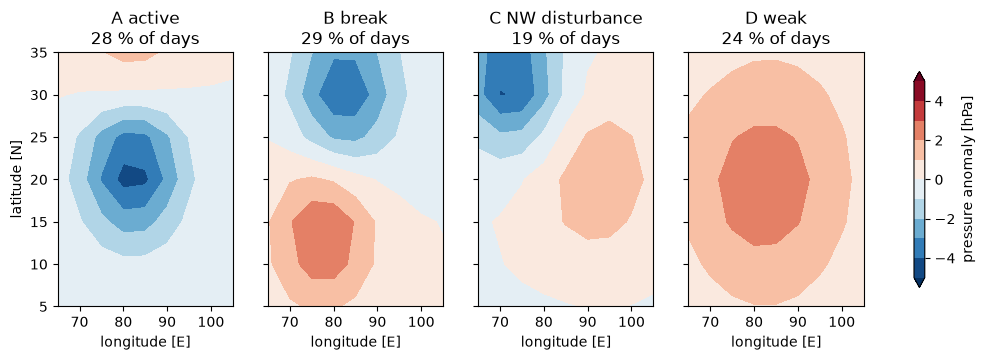

In [6]:
# Name the clusters by matching them to the true types (only possible because the data are synthetic)
conf = np.zeros((4, 4), int)
np.add.at(conf, (lab, t_true), 1)
r_, c_ = linear_sum_assignment(-conf)
perm = dict(zip(r_, c_))                                  # cluster -> true type
lab_n = np.array([perm[l] for l in lab])                  # labels now share the numbering of type_names
print(pd.crosstab(pd.Series([type_names[i] for i in t_true], name="true type"),
                  pd.Series([type_names[i] for i in lab_n], name="cluster")))
print(f"days placed in the matching cluster: {100 * np.mean(lab_n == t_true):.1f} %")

comp = np.stack([field[lab_n == k].mean(0) for k in range(4)])        # composite (mean) anomaly of each cluster
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=True)
for k, a in enumerate(axes):
    im = a.contourf(lon, lat, comp[k], levels=np.linspace(-5, 5, 11), cmap="RdBu_r", extend="both")
    a.set_title(f"{type_names[k]}\n{100 * np.mean(lab_n == k):.0f} % of days"); a.set_xlabel("longitude [E]")
    a.grid(False)
axes[0].set_ylabel("latitude [N]")
fig.colorbar(im, ax=axes, label="pressure anomaly [hPa]", shrink=0.85)

In [7]:
# The same numbers as the KMeans sheet of the workbook: 12 points, 3 clusters, poor starting centroids
pts = read_data("kmeans_points.csv")
Xp = pts[["PC1", "PC2"]].to_numpy()
Cc = Xp[[int(pts.index[pts.init_centroid == j][0]) for j in (1, 2, 3)]].copy()
for it in range(1, 5):
    d = np.sqrt(((Xp[:, None, :] - Cc[None]) ** 2).sum(2))
    a = d.argmin(1) + 1
    wss = (d.min(1) ** 2).sum()
    Cn = np.array([Xp[a == k].mean(0) for k in (1, 2, 3)])
    print(f"iteration {it}: WSS = {wss:7.3f}  clusters = {a.tolist()}  new centroids = {np.round(Cn, 3).tolist()}")
    Cc = Cn

iteration 1: WSS =  25.360  clusters = [1, 2, 1, 2, 2, 3, 2, 3, 3, 3, 3, 3]  new centroids = [[-1.65, 1.35], [0.05, 1.3], [0.333, -0.667]]
iteration 2: WSS =  11.592  clusters = [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3]  new centroids = [[-1.35, 1.15], [1.15, 1.25], [-0.075, -1.425]]
iteration 3: WSS =   3.255  clusters = [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3]  new centroids = [[-1.35, 1.15], [1.15, 1.25], [-0.075, -1.425]]
iteration 4: WSS =   3.255  clusters = [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3]  new centroids = [[-1.35, 1.15], [1.15, 1.25], [-0.075, -1.425]]


The workbook shows the same WSS values, 25.360, 11.592, 3.255, 3.255: the first iteration moves most points, the second repairs the poor start, and by the fourth the assignments no longer change. (The sheet was recalculated by an independent formula engine and checked against this code, but not opened in Excel itself.)

# 4) Daily rainfall conditional on the weather type

Once each day has a type, rainfall is modelled **given the type**. Let $T_t$ be the type, $W_t$ the wet-day indicator and $R_t$ the rainfall depth (mm) on day $t$.

1. **Type sequence.** A first-order Markov chain, $P_{kl} = \Pr(T_{t+1}=l \mid T_t=k)$. Counting transitions in the classified record gives the maximum-likelihood estimate $\hat P_{kl} = n_{kl}/\sum_l n_{kl}$. Types persist for several days (an active monsoon spell), and the chain reproduces that.
2. **Occurrence.** $\Pr(W_t = 1 \mid T_t = k) = p_k$, the fraction of days of type $k$ that were wet.
3. **Amount.** On a wet day of type $k$, $R_t \sim \text{Gamma}$ with mean $m_k$ and standard deviation $\sigma_k$. The gamma shape and scale follow by the method of moments, $\alpha_k = m_k^2/\sigma_k^2$, $\theta_k = \sigma_k^2/m_k$. (A simpler choice is the exponential distribution, $R = -m_k \ln(1-u)$ for a uniform $u$.)

A type sequence is generated step by step: draw $u \sim U(0,1)$ and pick the first type whose cumulative transition probability in the row of the previous type is at least $u$ (the same inverse-cdf device used for the kNN weights below). Then draw the occurrence and the amount.

**Long-run behaviour.** The long-run frequency $\pi_k$ of each type satisfies $\pi = \pi P$ with $\sum_k \pi_k = 1$, so $\pi$ is the left eigenvector of $P$ for eigenvalue 1. By the law of total expectation, the long-run mean daily rainfall is

$$\mathbb{E}[R] = \sum_{k} \pi_k\, p_k\, m_k .$$

This one formula contains the whole story of how a changed climate can change rainfall in this framework: through $\pi$ (the types occur more or less often), through $p_k$ and $m_k$ (the same type rains differently), or both. The code below fits these quantities from the (synthetic) classified record and checks the formula.

In [8]:
K = 4
N = np.zeros((K, K))
for a_, b_ in zip(lab_n[:-1], lab_n[1:]): N[a_, b_] += 1
P_hat = N / N.sum(1, keepdims=True)
wetday = rain > 0
p_hat = np.array([wetday[lab_n == k].mean() for k in range(K)])
m_hat = np.array([rain[(lab_n == k) & wetday].mean() for k in range(K)])
s_hat = np.array([rain[(lab_n == k) & wetday].std(ddof=1) for k in range(K)])
w_, v_ = np.linalg.eig(P_hat.T)
pi_hat = np.real(v_[:, np.argmax(np.real(w_))]); pi_hat /= pi_hat.sum()
freq = np.bincount(lab_n, minlength=K) / len(lab_n)

tab = pd.DataFrame({"days [%]": 100 * freq, "pi (eigenvector) [%]": 100 * pi_hat, "p_wet": p_hat,
                    "mean wet-day rain [mm]": m_hat, "sd [mm]": s_hat}, index=type_names).round(2)
print(tab)
print("\nestimated transition matrix P:\n", np.round(P_hat, 2))
print(f"\nE[R] = sum(pi p m) = {np.sum(pi_hat * p_hat * m_hat):.3f} mm/day   vs record mean {rain.mean():.3f} mm/day")

def simulate(P, p_wet, mean, sd, n, rng):
    shape, scale = mean ** 2 / sd ** 2, sd ** 2 / mean
    cum = np.cumsum(P, axis=1)
    T = np.empty(n, int); T[0] = rng.choice(len(P), p=pi_hat)
    u = rng.random((n, 2)); g = rng.gamma(shape[None, :].repeat(n, 0), scale[None, :].repeat(n, 0))
    R = np.zeros(n)
    for t in range(n):
        if t > 0: T[t] = min(np.searchsorted(cum[T[t - 1]], u[t, 0]), len(P) - 1)
        if u[t, 1] < p_wet[T[t]]: R[t] = g[t, T[t]]
    return T, R

sim_T, sim_R = simulate(P_hat, p_hat, m_hat, s_hat, 20 * 365, np.random.default_rng(1))

def stats(R):
    r = R.reshape(20, 365); wd = (R > 0).astype(float)
    return {"mean annual rain [mm]": r.sum(1).mean(), "wet-day fraction": wd.mean(), "99th pct of wet days [mm]": np.percentile(R[R > 0], 99),
            "mean annual max daily [mm]": r.max(1).mean(), "lag-1 corr. of occurrence": np.corrcoef(wd[:-1], wd[1:])[0, 1]}
# a type-blind generator: independent days with the overall wet fraction and amount distribution
iid = np.where(np.random.default_rng(2).random(20 * 365) < wetday.mean(), np.random.default_rng(3).choice(rain[wetday], 20 * 365), 0.0)
print()
print(pd.DataFrame({"observed (synthetic)": stats(rain[:20 * 365]), "weather-type model": stats(sim_R), "independent days": stats(iid)}).round(3))

                  days [%]  pi (eigenvector) [%]  p_wet  \
A active             28.29                 28.28   0.78   
B break              28.82                 28.83   0.25   
C NW disturbance     18.78                 18.78   0.37   
D weak               24.11                 24.11   0.11   

                  mean wet-day rain [mm]  sd [mm]  
A active                           11.55    12.79  
B break                             3.94     4.51  
C NW disturbance                    5.68     6.31  
D weak                              4.06     7.61  

estimated transition matrix P:
 [[0.66 0.12 0.08 0.14]
 [0.12 0.57 0.14 0.17]
 [0.1  0.21 0.44 0.25]
 [0.17 0.21 0.18 0.43]]

E[R] = sum(pi p m) = 3.328 mm/day   vs record mean 3.329 mm/day

                            observed (synthetic)  weather-type model  \
mean annual rain [mm]                   1215.137            1147.510   
wet-day fraction                           0.387               0.390   
99th pct of wet days [mm]           

The type model recovers the wet-day fraction and, within the noise of a single 20-year realisation, the annual rainfall and the extremes (a few per cent low here, partly because the fitted types mix days of different regimes after the 90 % correct classification). It also recovers most of the **persistence** of wet and dry days (lag-1 correlation 0.14 against 0.18), which comes entirely from the type chain; a generator that ignores the types and draws independent days gives 0.01. This is the first practical advantage of weather types: temporal structure arrives with the circulation.

# 5) The future climate, and what weather types cannot do

To project, the observed classification rules (the PCA loadings, the standardisation and the cluster centroids of the *observed* period) are applied unchanged to the climate model's circulation fields of the future period. The fields must be expressed as anomalies from the model's own climatology, so that the model's mean bias does not push every day into one type. Two kinds of change then feed the generator:

1. **Change of frequency.** The model's type sequence has a different $\pi$ (or different persistence $P$) in the future: more break-monsoon days, fewer active ones.
2. **Change of type-conditional rainfall.** The same circulation may give more rain per wet day in a warmer, moister atmosphere. This does not come from the circulation at all, so it has to be added from a thermodynamic argument, for example by scaling $m_k$ by about 7 % per kelvin of warming (the Clausius&ndash;Clapeyron rate of the saturation vapour pressure; a rough guide, not a rule).

The code below imposes both changes by hand on the fitted generator, using the formula $\mathbb{E}[R]=\sum \pi_k p_k m_k$ to explain the outcome.

**The limitation to keep in mind: the method can only recombine what it has seen.** Every day of the future is assigned to one of the $K$ observed types, so a circulation that never occurred in the record (a new type) is forced into the nearest old one, and its rainfall is the old type's. A useful safeguard is to measure how far a future day lies from its centroid and flag days that are farther than almost any observed day of that type. The last panel shows the idea with one invented, unprecedented field.

pi baseline: [0.283 0.288 0.188 0.241]  pi future: [0.17  0.394 0.18  0.256]
E[R] baseline 3.328, frequency only 2.409, intensity only 3.811, both 2.759 mm/day
baseline                               mean annual rain    1245 mm  ( +0.0 %)
fewer active days (frequency only)     mean annual rain     890 mm  (-28.5 %)
wetter types only (+14 %)              mean annual rain    1397 mm  (+12.2 %)
both                                   mean annual rain    1011 mm  (-18.8 %)
novel field: nearest centroid is cluster 2 at distance 17.0; 99.9th percentile of observed distances 10.4


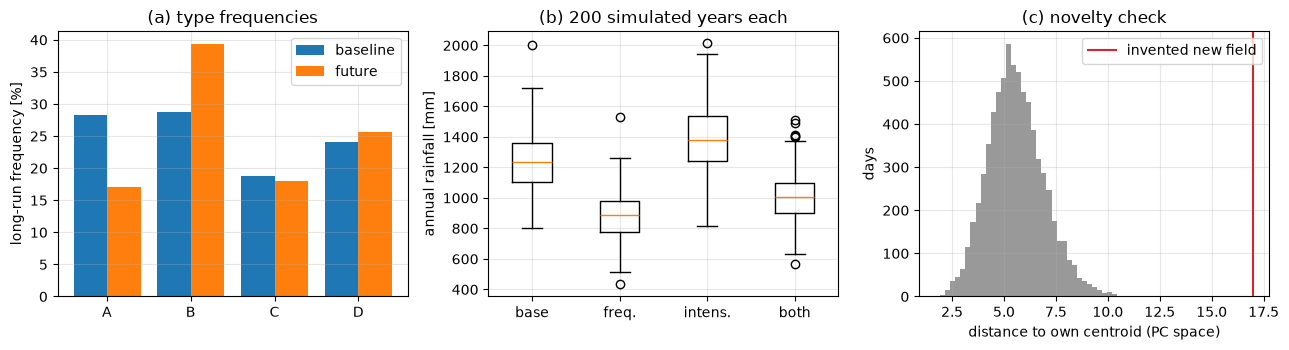

In [9]:
def stationary(P):
    w, v = np.linalg.eig(P.T); x = np.real(v[:, np.argmax(np.real(w))]); return x / x.sum()

tilt = np.array([0.75, 1.30, 1.0, 1.10])                 # relative preference for each type in the future
P_fut = P_hat * tilt[None, :]; P_fut /= P_fut.sum(1, keepdims=True)
pi_fut = stationary(P_fut)
m_fut = m_hat * 1.07 ** 2                                # +2 K at about 7 %/K, applied to every type

n_sim = 200 * 365
runs = {"baseline": (P_hat, m_hat), "fewer active days (frequency only)": (P_fut, m_hat),
        "wetter types only (+14 %)": (P_hat, m_fut), "both": (P_fut, m_fut)}
ann = {}
for i, (name, (P_, m_)) in enumerate(runs.items()):
    _, R = simulate(P_, p_hat, m_, s_hat * m_ / m_hat, n_sim, np.random.default_rng(10 + i))
    ann[name] = R.reshape(200, 365).sum(1)
print("pi baseline:", np.round(pi_hat, 3), " pi future:", np.round(pi_fut, 3))
print(f"E[R] baseline {np.sum(pi_hat * p_hat * m_hat):.3f}, frequency only {np.sum(pi_fut * p_hat * m_hat):.3f}, "
      f"intensity only {np.sum(pi_hat * p_hat * m_fut):.3f}, both {np.sum(pi_fut * p_hat * m_fut):.3f} mm/day")
for name, a_ in ann.items():
    print(f"{name:38s} mean annual rain {a_.mean():7.0f} mm  ({100 * (a_.mean() / ann['baseline'].mean() - 1):+5.1f} %)")

# novelty check: distance of each day to its own centroid, and of an invented, unprecedented field
dist_own = np.sqrt(((Y - cent[lab]) ** 2).sum(1))
new_field = blob(10, 95, -16.0, 4.0, 5.0) + blob(30, 70, 12.0, 4.0, 5.0)           # a pattern never seen
zn = ((new_field.ravel() - X.mean(0)) / X.std(0, ddof=1)) @ W[:, :M]
d_new = np.sqrt(((zn[None] - cent) ** 2).sum(1))
print(f"novel field: nearest centroid is cluster {d_new.argmin()} at distance {d_new.min():.1f}; "
      f"99.9th percentile of observed distances {np.percentile(dist_own, 99.9):.1f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
xk = np.arange(K); ax[0].bar(xk - 0.2, 100 * pi_hat, 0.4, label="baseline"); ax[0].bar(xk + 0.2, 100 * pi_fut, 0.4, label="future")
ax[0].set_xticks(xk); ax[0].set_xticklabels([n.split()[0] for n in type_names]); ax[0].set_ylabel("long-run frequency [%]"); ax[0].legend(); ax[0].set_title("(a) type frequencies")
ax[1].boxplot(list(ann.values())); ax[1].set_xticklabels(["base", "freq.", "intens.", "both"]); ax[1].set_ylabel("annual rainfall [mm]"); ax[1].set_title("(b) 200 simulated years each")
ax[2].hist(dist_own, bins=40, color="0.6"); ax[2].axvline(d_new.min(), color="tab:red", label="invented new field")
ax[2].set_xlabel("distance to own centroid (PC space)"); ax[2].set_ylabel("days"); ax[2].legend(); ax[2].set_title("(c) novelty check")
fig.tight_layout()

# PART B. Temporal downscaling

# 6) Why hourly rainfall matters, and our synthetic record

A catchment with a time of concentration of one hour, a city drain, a culvert on a hill road: for these the *intensity over a short duration* decides the design flood, not the daily depth. Design uses **intensity&ndash;duration&ndash;frequency (IDF)** curves, that is, the rainfall depth or intensity of a given duration (1 h, 3 h, 6 h, 24 h) expected once in $T$ years. IDF curves need hourly or finer records, which are short, patchy and missing in many places, while rain gauges report daily totals almost everywhere, and global and regional climate models and many gridded products (Lecture 15) are daily or coarser. **Temporal downscaling** turns a daily series into an hourly one that has the right statistics.

Two requirements follow from this purpose:

1. **Additivity.** The 24 hourly values must add up to the given daily total. Otherwise we have changed the water balance that the daily model delivered.
2. **Realistic sub-daily structure.** The hourly values must reproduce the diurnal cycle (in much of India monsoon convection peaks in the late afternoon and evening), the share of wet hours, the heavy short bursts, and, ideally, the dependence between consecutive hours.

### Synthetic hourly record

We build a 40-year record of the 122 days of June to September. A two-state Markov chain makes active and break spells; on each day a Poisson number of storms start, mostly in the afternoon peak but also at any hour; each storm has a gamma-distributed depth, a duration that grows with the square root of the depth, and a skewed hump-shaped intensity profile (a beta density). Storms cross midnight. Values are rounded to the gauge resolution of 0.1 mm. The first 20 years are the **library** of observed days from which patterns will be borrowed; the last 20 years play the role of the "truth" that we try to recover from the daily totals alone.

To use real data, load an hourly gauge record, reshape it to days by 24 hours, and use the same split.

library 2440 days, 1250 wet; test 2440 days, 1191 wet
mean daily rain 8.4 mm, wet-hour fraction (>= 0.1 mm) 0.093, wettest hour 51.1 mm
mean annual maximum: 1-hour 23.4 mm, 1-day 74.6 mm  -> a daily record misses the burst intensity


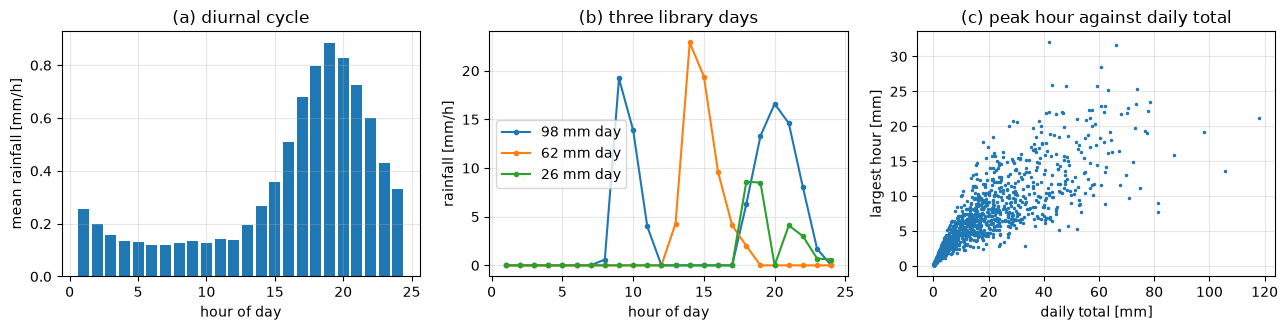

In [10]:
def make_hourly(n_years=40, days=122, seed=7):
    rg = np.random.default_rng(seed)
    nd = n_years * days
    H = np.zeros(nd * 24 + 48)
    regime = np.zeros(nd, int)
    for d in range(1, nd):                                   # active (1) / break (0) spells
        stay = 0.85 if regime[d - 1] == 1 else 0.80
        regime[d] = regime[d - 1] if rg.random() < stay else 1 - regime[d - 1]
    rate = np.where(regime == 1, 1.1, 0.25)                  # storms per day
    for d in range(nd):
        for _ in range(rg.poisson(rate[d])):
            s = (rg.normal(17, 2.5) if rg.random() < 0.65 else rg.uniform(0, 24)) % 24    # start hour
            depth = rg.gamma(0.8, 14.0)                      # storm depth [mm]
            dur = max(0.7, 0.8 * depth ** 0.5 * rg.lognormal(0, 0.45))                    # duration [h]
            a, b = rg.uniform(1.0, 2.5), rg.uniform(1.0, 3.5)                             # profile shape
            t0 = d * 24 + s
            edges = np.arange(np.floor(t0), np.ceil(t0 + dur) + 1)
            frac = np.diff(beta_dist.cdf(np.clip((edges - t0) / dur, 0, 1), a, b))        # share of the storm in each hour
            H[int(edges[0]): int(edges[0]) + len(frac)] += depth * frac
    return np.round(H[: nd * 24], 1).reshape(nd, 24)

dpy = 122
Hh = make_hourly()
Hl, Ht = Hh[: 20 * dpy], Hh[20 * dpy:]                       # library years and test years
yl, yt = Hl.sum(1), Ht.sum(1)                                # daily totals [mm]
print(f"library {len(yl)} days, {np.sum(yl > 0)} wet; test {len(yt)} days, {np.sum(yt > 0)} wet")
print(f"mean daily rain {Hh.sum(1).mean():.1f} mm, wet-hour fraction (>= 0.1 mm) {(Hh >= 0.1).mean():.3f}, wettest hour {Hh.max():.1f} mm")
am1 = Hh.reshape(40, -1).max(1).mean(); amd = Hh.sum(1).reshape(40, dpy).max(1).mean()
print(f"mean annual maximum: 1-hour {am1:.1f} mm, 1-day {amd:.1f} mm  -> a daily record misses the burst intensity")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].bar(np.arange(1, 25), Hh.mean(0)); ax[0].set_xlabel("hour of day"); ax[0].set_ylabel("mean rainfall [mm/h]"); ax[0].set_title("(a) diurnal cycle")
for d in np.argsort(yl)[[-3, -30, -300]]:
    ax[1].plot(np.arange(1, 25), Hl[d], marker="o", ms=3, label=f"{yl[d]:.0f} mm day")
ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("rainfall [mm/h]"); ax[1].legend(); ax[1].set_title("(b) three library days")
ax[2].plot(yl[yl > 0], Hl[yl > 0].max(1), ".", ms=3); ax[2].set_xlabel("daily total [mm]"); ax[2].set_ylabel("largest hour [mm]"); ax[2].set_title("(c) peak hour against daily total")
fig.tight_layout()

# 7) k-nearest-neighbour resampling

**The task.** We know a predictor (feature) vector $x_t$ for a time we want to simulate, and a library of observed pairs $(x_i, y_i)$, $i=1,\dots,n$. We want to draw a value of the unknown $y_t$ from its conditional distribution given $x_t$, *without assuming a distribution*. The nonparametric answer is to look at the library days whose features resemble $x_t$ and to resample from their $y_i$. For example, $x$ is the daily total and $y$ the hourly pattern; or $x$ is the wind direction and $y$ the monthly rainfall.

**Algorithm.**

1. **Distance.** For each library day compute the distance to the target. With several features use the Mahalanobis distance
$$D_i = (x_t - x_i)^{\mathsf T}\, C^{-1}\,(x_t - x_i),$$
where $C$ is the covariance matrix of the features. It removes the effect of units and of correlation between features; if the features are uncorrelated it is the sum of squared differences in units of the standard deviation, and with one feature it is just $(x_t - x_i)^2$ up to a constant. Only the *ranking* of the distances matters below.
2. **Neighbours.** Sort the $D_i$ and keep the $k$ smallest. Call the neighbour with the $j$-th smallest distance "neighbour $j$" and its index $i_{(j)}$.
3. **Kernel weights.** Give neighbour $j$ the probability
$$w_j = \frac{1/j}{\sum_{m=1}^{k} 1/m}, \qquad j = 1,\dots,k .$$
4. **Draw.** Form the cumulative weights $c_j = \sum_{m \le j} w_m$ and draw $u \sim U(0,1)$. Choose $j^*$ as the smallest $j$ with $c_j \ge u$. Then $\Pr(j^* = j) = c_j - c_{j-1} = w_j$, as required. Return $y_t = y_{i_{(j^*)}}$.

**Choosing $k$.** A kNN estimate should use more neighbours as the library grows ($k \to \infty$) but a vanishing fraction of it ($k/n \to 0$), so that the neighbours are both numerous enough to average out noise and close enough to be relevant. The square-root rule $k = \lceil \sqrt{n} \rceil$ satisfies both and is the usual default; results change little within a factor of two.

**Why the weights $1/j$?** Suppose the library is dense and the density of the feature is locally constant, $f$. In one dimension the interval of half-width $r$ around $x_t$ holds about $2 n f r$ points, so the $j$-th neighbour lies at distance $r_j \approx j/(2nf)$: the *rank is proportional to the distance*. The weight $1/j$ is therefore proportional to $1/r_j$: close neighbours count more, but the weight falls off slowly, so that a handful of near neighbours are not copied over and over. The normalising sum is the harmonic number $H_k = \sum_{m\le k} 1/m \approx \ln k + 0.577$, so for $k=5$ the nearest neighbour is chosen with probability $1/H_5 = 0.438$ and for $k = 30$ with $0.25$. Because the weight depends on the rank and not on the distance itself, the kernel automatically widens where data are sparse. It is a heuristic; the experiment below tests it numerically against two alternatives, the uniform kernel $w_j = 1/k$ and the steeper $w_j \propto 1/j^2$.

**The experiment.** We use a known nonlinear relation $y = f(x) + \varepsilon$ with a noise that varies with $x$, a library of $n=300$ pairs, and estimate the conditional mean $\hat m(x_0) = \sum_j w_j\, y_{(j)}$ and the conditional spread at 21 target values $x_0$, for 60 random libraries. We report the root-mean-square error of $\hat m$ and the ratio of the resampled spread to the true noise standard deviation (the ideal ratio is 1).

j (k = 10)      1      2      3      4      5      6      7      8      9   \
uniform 1/k  0.100  0.100  0.100  0.100  0.100  0.100  0.100  0.100  0.100   
1/j          0.341  0.171  0.114  0.085  0.068  0.057  0.049  0.043  0.038   
1/j^2        0.645  0.161  0.072  0.040  0.026  0.018  0.013  0.010  0.008   

j (k = 10)      10  
uniform 1/k  0.100  
1/j          0.034  
1/j^2        0.006  
uniform 1/k  spread ratio at k = 40: 1.42; at k = 100: 2.46
1/j          spread ratio at k = 40: 1.14; at k = 100: 1.68
1/j^2        spread ratio at k = 40: 0.80; at k = 100: 0.85
uniform 1/k  RMSE: best 0.21 at k =  25; over k = 12..60 it ranges 0.21 to 0.46
1/j          RMSE: best 0.26 at k =  40; over k = 12..60 it ranges 0.26 to 0.33
1/j^2        RMSE: best 0.51 at k = 100; over k = 12..60 it ranges 0.51 to 0.53


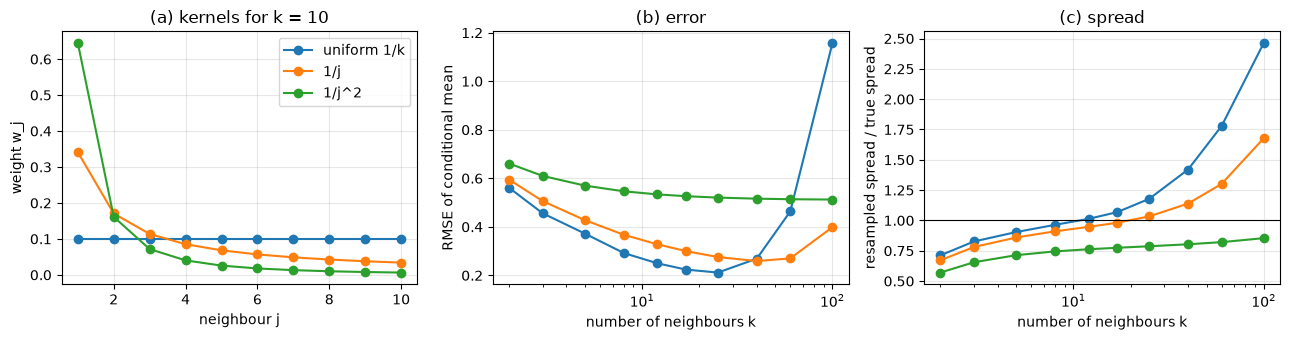

In [11]:
fn = lambda x: 3 * np.sin(1.5 * x) + 0.5 * x
sdn = lambda x: 0.6 + 0.3 * np.abs(np.sin(x))
kernels = {"uniform 1/k": lambda k: np.ones(k) / k,
           "1/j": lambda k: (1 / np.arange(1, k + 1)) / np.sum(1 / np.arange(1, k + 1)),
           "1/j^2": lambda k: (1 / np.arange(1, k + 1) ** 2) / np.sum(1 / np.arange(1, k + 1) ** 2)}
ks = [2, 3, 5, 8, 12, 17, 25, 40, 60, 100]
x0 = np.linspace(-3, 3, 21); nlib, R = 300, 60
rg = np.random.default_rng(0)
sq_err = {m: np.zeros(len(ks)) for m in kernels}; spread = {m: np.zeros(len(ks)) for m in kernels}
for _ in range(R):
    xs = rg.uniform(-3.5, 3.5, nlib); ys = fn(xs) + sdn(xs) * rg.standard_normal(nlib)
    order = np.argsort(np.abs(xs[None, :] - x0[:, None]), axis=1)[:, :max(ks)]       # neighbours of every x0
    for a, k in enumerate(ks):
        yy = ys[order[:, :k]]                                                         # (21, k) neighbour values
        for m, kf in kernels.items():
            w = kf(k); mh = yy @ w
            sq_err[m][a] += np.mean((mh - fn(x0)) ** 2)
            spread[m][a] += np.sqrt(np.mean(((yy - mh[:, None]) ** 2) @ w)) / np.mean(sdn(x0))

w10 = pd.DataFrame({m: kf(10) for m, kf in kernels.items()}, index=np.arange(1, 11)).round(3)
w10.index.name = "j (k = 10)"; print(w10.T)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for m in kernels:
    ax[0].plot(np.arange(1, 11), kernels[m](10), "o-", label=m)
    ax[1].plot(ks, np.sqrt(sq_err[m] / R), "o-", label=m); ax[2].plot(ks, spread[m] / R, "o-", label=m)
ax[0].set_xlabel("neighbour j"); ax[0].set_ylabel("weight w_j"); ax[0].set_title("(a) kernels for k = 10"); ax[0].legend()
ax[1].set_xscale("log"); ax[1].set_xlabel("number of neighbours k"); ax[1].set_ylabel("RMSE of conditional mean"); ax[1].set_title("(b) error")
ax[2].set_xscale("log"); ax[2].axhline(1, color="k", lw=0.8); ax[2].set_xlabel("number of neighbours k"); ax[2].set_ylabel("resampled spread / true spread"); ax[2].set_title("(c) spread")
fig.tight_layout()
i40 = ks.index(40)
for m in kernels:
    e = np.sqrt(sq_err[m] / R); print(f"{m:12s} spread ratio at k = 40: {spread[m][i40] / R:.2f}; at k = 100: {spread[m][-1] / R:.2f}")
for m in kernels:
    e = np.sqrt(sq_err[m] / R); print(f"{m:12s} RMSE: best {e.min():.2f} at k = {ks[e.argmin()]:3d}; over k = 12..60 it ranges {e[4:9].min():.2f} to {e[4:9].max():.2f}")

Read the figure with care. With its best $k$ the uniform kernel has the lowest error here, but its error and its spread change a lot with $k$: it overestimates the spread by about 40 % at $k=40$ and its error is five times larger at $k=100$, because distant points get the same weight as close ones. The steep $1/j^2$ kernel is almost independent of $k$, but only because it copies the one or two nearest points: its error is high and its spread is too small, so the resampled series would have too little variability. The $1/j$ kernel is in between, with a spread near the true value and an error that stays within a narrow band over a wide range of $k$. That insensitivity is what makes it a good **default**: one need not tune $k$ carefully. It is not optimal for every problem.

# 8) Daily to hourly: resampling the pattern and rescaling

For temporal downscaling the library holds $n$ observed wet days, each with 24 hourly depths $x_{i,h}$, $h=1,\dots,24$ (mm), and daily total $y_i = \sum_h x_{i,h}$. The target is a daily total $y_t$ for a day $t$ whose hourly values we do not know.

1. **Neighbours** by $D_i = (y_t - y_i)^2$ (the single feature is the daily total). Keep the $k = \lceil\sqrt n\rceil$ closest, weight them with $1/j$, and draw one library day $p$ with the cumulative-weight rule of Section 7.
2. **Take the pattern, not the depth.** Write the *fraction* of the day's rain falling in hour $h$ as $f_{p,h} = x_{p,h}/y_p$, so that $\sum_h f_{p,h} = 1$. The downscaled hourly value is
$$X_{t,h} = f_{p,h}\; y_t = x_{p,h}\,\frac{y_t}{y_p}.$$

**Proportional adjustment preserves the daily total.** Summing over the day,
$$\sum_{h=1}^{24} X_{t,h} = \frac{y_t}{y_p}\sum_{h=1}^{24} x_{p,h} = \frac{y_t}{y_p}\,y_p = y_t .$$
This holds for every draw, exactly, whatever the scale factor $s = y_t/y_p$. Dry hours stay dry (zero times $s$ is zero) and the diurnal timing of the chosen day is kept.

**What it does to the extremes.** The hourly maximum of the target day is $X_{t,\max} = y_t \max_h f_{p,h}$. Two things follow.
- The peak is $y_t$ times the *peak fraction* of the borrowed day. It lies between $y_t/24$ (rain spread evenly) and $y_t$ (everything in one hour). The distribution of hourly extremes is the distribution of peak fractions among days of similar total, scaled by $y_t$. This is why matching on the daily total matters: big days tend to have different patterns from small days (panel (c) of the data figure shows that the largest hour grows less than in proportion to the daily total).
- If the target total lies beyond the largest library day, $s>1$ and the pattern comes from a smaller day. If extreme days are more peaked than moderate ones, the extremes are then underestimated. Proportional scaling also multiplies the small hourly values, so hours near the gauge resolution can cross the wet-hour threshold when $s \ne 1$; the wet-hour count is therefore preserved only approximately.

**Neighbouring days.** Heavy rain often continues across midnight, but a pattern taken from one day knows nothing about the day before or after. A common remedy is to add the totals of the previous and next day to the feature vector, $x_t = (\sqrt{y_t},\ c\sqrt{y_{t-1}},\ c\sqrt{y_{t+1}})$, so that days with a similar neighbourhood are preferred (square roots tame the large totals). We use $c = 0.5$ below as the "with neighbours" variant.

(Lee and Jeong's version of the method adds a genetic-algorithm mixing step that crosses over and mutates hours between two resampled patterns before the adjustment, to produce patterns not present in the library. We do not use it here.)

### One day by hand: the same example as the workbook

The `kNN_Resample` sheet disaggregates a target of 46 mm using 20 library days (file `knn_library_hourly.csv`) and the fixed random number $u = 0.62$. The cell reproduces every step.

   library day  total y_i [mm]  D [mm^2]  weight w_j  cumulative
j                                                               
1           16            43.0      9.00      0.4380      0.4380
2           13            49.7     13.69      0.2190      0.6569
3            9            38.7     53.29      0.1460      0.8029
4            3            55.3     86.49      0.1095      0.9124
5           18            34.1    141.61      0.0876      1.0000

n = 20, k = ceil(sqrt(n)) = 5; u = 0.62 lies between c_1 = 0.4380 and c_2 = 0.6569 -> neighbour j* = 2
chosen day 13, y_p = 49.7 mm, scale s = 0.9256
sum of hourly values = 46.0000 mm (target 46.0); largest hour 13.5 -> 12.49 mm


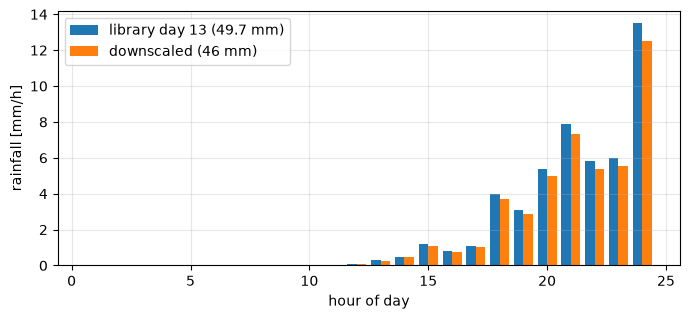

In [12]:
lib = read_data("knn_library_hourly.csv")
Hlib = lib.iloc[:, 1:].to_numpy(); ylib = Hlib.sum(1)
y_target, u = 46.0, 0.62
n = len(ylib); k = int(np.ceil(np.sqrt(n)))
D = (y_target - ylib) ** 2
order = np.argsort(D, kind="stable")[:k]                      # neighbours 1..k (library row indices)
w = 1 / np.arange(1, k + 1); w /= w.sum()
cw = np.cumsum(w)
jstar = int(np.searchsorted(cw, u) + 1)                       # first j with cumulative weight >= u
p = order[jstar - 1]; s = y_target / ylib[p]
X_hr = Hlib[p] * s

table = pd.DataFrame({"library day": lib["day"].to_numpy()[order], "total y_i [mm]": ylib[order].round(1), "D [mm^2]": D[order].round(2),
                      "weight w_j": w.round(4), "cumulative": cw.round(4)}, index=pd.Index(np.arange(1, k + 1), name="j"))
print(table)
print(f"\nn = {n}, k = ceil(sqrt(n)) = {k}; u = {u} lies between c_{jstar-1} = {cw[jstar-2]:.4f} and c_{jstar} = {cw[jstar-1]:.4f} -> neighbour j* = {jstar}")
print(f"chosen day {lib['day'][p]}, y_p = {ylib[p]:.1f} mm, scale s = {s:.4f}")
print(f"sum of hourly values = {X_hr.sum():.4f} mm (target {y_target}); largest hour {Hlib[p].max():.1f} -> {X_hr.max():.2f} mm")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.bar(np.arange(1, 25) - 0.2, Hlib[p], 0.4, label=f"library day {lib['day'][p]} ({ylib[p]:.1f} mm)")
ax.bar(np.arange(1, 25) + 0.2, X_hr, 0.4, label=f"downscaled ({y_target:.0f} mm)")
ax.set_xlabel("hour of day"); ax.set_ylabel("rainfall [mm/h]"); ax.legend(); fig.tight_layout()

# 9) Validating the disaggregation

We now disaggregate the **test** years (20 years, 2440 days) from their daily totals alone, borrowing patterns only from the library years, and compare with the true hourly test record. Four versions are compared:

- **kNN, daily total only** (Section 8),
- **kNN with neighbouring days** (the three-feature version),
- **flat**: every wet day spread evenly, $X_h = y_t/24$ (the simplest additive rule),
- **mean profile**: $X_h = y_t \bar f_h$ with the average diurnal fraction of the library.

The checks are the ones a designer cares about: the share of wet hours, the distribution of hourly intensities, the annual maximum of the 1, 3, 6, 12 and 24 hour rainfall (the ingredients of an IDF curve; a full IDF would fit an extreme-value distribution to these maxima), the mean diurnal cycle, and the autocorrelation of the hourly series. Because one 20-year realisation is itself random, the kNN results are repeated 20 times and shown as a band.

In [13]:
def kernel_w(k):
    w = 1 / np.arange(1, k + 1); return w / w.sum()

def disagg(y, ylib_, Hlib_, rg, feats=None, flib=None):
    # kNN disaggregation of the daily totals y; the library holds daily totals ylib_ and hourly patterns Hlib_
    nl = len(ylib_); k = int(np.ceil(np.sqrt(nl))); cw = np.cumsum(kernel_w(k))
    out = np.zeros((len(y), 24)); u_ = rg.random(len(y))
    for t in np.where(y > 0)[0]:
        Dt = (y[t] - ylib_) ** 2 if feats is None else ((feats[t] - flib) ** 2).sum(1)
        nb = np.argpartition(Dt, k)[:k]; nb = nb[np.argsort(Dt[nb], kind="stable")]       # neighbours ordered by distance
        j = min(np.searchsorted(cw, u_[t]), k - 1); pj = nb[j]
        out[t] = Hlib_[pj] * y[t] / ylib_[pj]                                              # proportional adjustment
    return out

def feat3(yd, c=0.5):
    sq = np.sqrt(yd); return np.c_[sq, c * np.r_[0, sq[:-1]], c * np.r_[sq[1:], 0]]

wl = np.where(yl > 0)[0]                                      # wet library days
fl3 = feat3(yl)[wl]; ft3 = feat3(yt)
prof = Hl.sum(0) / Hl.sum()
sims = {"kNN, total only": [disagg(yt, yl[wl], Hl[wl], np.random.default_rng(s)) for s in range(20)],
        "kNN + neighbours": [disagg(yt, yl[wl], Hl[wl], np.random.default_rng(100 + s), ft3, fl3) for s in range(20)]}
flat = np.repeat(yt[:, None] / 24, 24, 1); meanp = yt[:, None] * prof[None, :]
print("additivity check, largest daily-total error over all days and runs [mm]:",
      max(np.abs(h.sum(1) - yt).max() for v in sims.values() for h in v))

def am(H, dur):                                               # annual maximum of the rolling `dur`-hour depth
    x = H.ravel(); c = np.r_[0, np.cumsum(x)]; r = c[dur:] - c[:-dur]
    return np.mean([r[i * 24 * dpy:(i + 1) * 24 * dpy - dur + 1].max() for i in range(len(x) // (24 * dpy))])
def acf(x, lag):
    x = x - x.mean(); return (x[:-lag] * x[lag:]).sum() / (x * x).sum()
def summary(H):
    x = H.ravel()
    return {"wet-hour fraction": (x >= 0.1).mean(), "mean 1-h annual max [mm]": am(H, 1), "mean 24-h annual max [mm]": am(H, 24),
            "lag-1 hourly autocorr.": acf(x, 1), "corr. hour 24 -> hour 1 next day": np.corrcoef(H[:-1, 23], H[1:, 0])[0, 1]}
rows = {"observed (test)": summary(Ht), "kNN, total only": summary(sims["kNN, total only"][0]),
        "kNN + neighbours": summary(sims["kNN + neighbours"][0]), "flat": summary(flat), "mean profile": summary(meanp)}
print(pd.DataFrame(rows).T.round(3))

additivity check, largest daily-total error over all days and runs [mm]: 2.842170943040401e-14
                  wet-hour fraction  mean 1-h annual max [mm]  \
observed (test)               0.088                    23.930   
kNN, total only               0.087                    24.738   
kNN + neighbours              0.086                    23.392   
flat                          0.409                     3.100   
mean profile                  0.383                     7.610   

                  mean 24-h annual max [mm]  lag-1 hourly autocorr.  \
observed (test)                      83.135                   0.665   
kNN, total only                      82.261                   0.638   
kNN + neighbours                     85.614                   0.643   
flat                                 74.410                   0.962   
mean profile                         74.410                   0.964   

                  corr. hour 24 -> hour 1 next day  
observed (test)                   

scale factors s = y_t / y_p over the k nearest neighbours: 5th, 50th, 95th percentile = [0.92 1.   1.09]


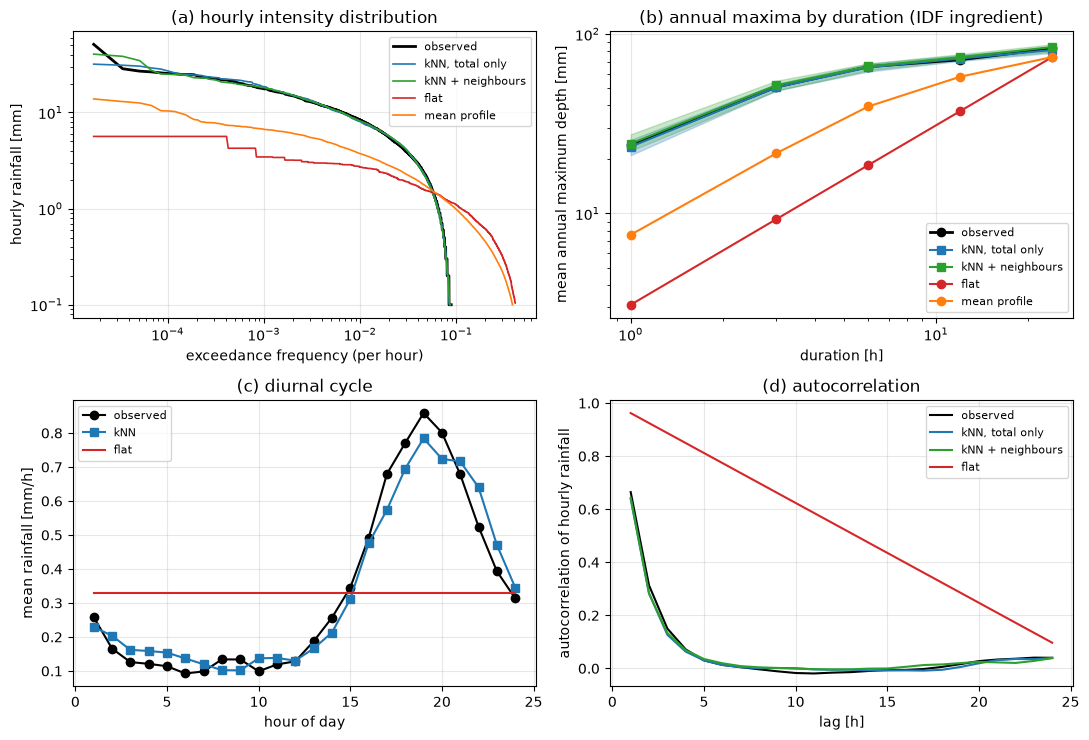

In [14]:
durs = [1, 3, 6, 12, 24]
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
qs = np.sort(Ht[Ht >= 0.1].ravel())[::-1]; ax[0, 0].loglog(np.arange(1, len(qs) + 1) / Ht.size, qs, "k", lw=2, label="observed")
for name, H, c in [("kNN, total only", sims["kNN, total only"][0], "tab:blue"), ("kNN + neighbours", sims["kNN + neighbours"][0], "tab:green"),
                   ("flat", flat, "tab:red"), ("mean profile", meanp, "tab:orange")]:
    q = np.sort(H[H >= 0.1].ravel())[::-1]; ax[0, 0].loglog(np.arange(1, len(q) + 1) / H.size, q, color=c, lw=1.2, label=name)
ax[0, 0].set_xlabel("exceedance frequency (per hour)"); ax[0, 0].set_ylabel("hourly rainfall [mm]"); ax[0, 0].legend(fontsize=8); ax[0, 0].set_title("(a) hourly intensity distribution")
obs_am = [am(Ht, d) for d in durs]
ax[0, 1].loglog(durs, obs_am, "k-o", lw=2, label="observed")
for name, c in [("kNN, total only", "tab:blue"), ("kNN + neighbours", "tab:green")]:
    A = np.array([[am(h, d) for d in durs] for h in sims[name]])
    ax[0, 1].fill_between(durs, A.min(0), A.max(0), color=c, alpha=0.25); ax[0, 1].loglog(durs, A.mean(0), color=c, marker="s", label=name)
ax[0, 1].loglog(durs, [am(flat, d) for d in durs], "o-", color="tab:red", label="flat"); ax[0, 1].loglog(durs, [am(meanp, d) for d in durs], "o-", color="tab:orange", label="mean profile")
ax[0, 1].set_xlabel("duration [h]"); ax[0, 1].set_ylabel("mean annual maximum depth [mm]"); ax[0, 1].legend(fontsize=8); ax[0, 1].set_title("(b) annual maxima by duration (IDF ingredient)")
ax[1, 0].plot(np.arange(1, 25), Ht.mean(0), "k-o", label="observed"); ax[1, 0].plot(np.arange(1, 25), sims["kNN, total only"][0].mean(0), "tab:blue", marker="s", label="kNN")
ax[1, 0].plot(np.arange(1, 25), flat.mean(0), color="tab:red", label="flat"); ax[1, 0].set_xlabel("hour of day"); ax[1, 0].set_ylabel("mean rainfall [mm/h]"); ax[1, 0].legend(fontsize=8); ax[1, 0].set_title("(c) diurnal cycle")
lags = np.arange(1, 25)
for name, H, c in [("observed", Ht, "k"), ("kNN, total only", sims["kNN, total only"][0], "tab:blue"), ("kNN + neighbours", sims["kNN + neighbours"][0], "tab:green"), ("flat", flat, "tab:red")]:
    ax[1, 1].plot(lags, [acf(H.ravel(), l) for l in lags], color=c, label=name)
ax[1, 1].set_xlabel("lag [h]"); ax[1, 1].set_ylabel("autocorrelation of hourly rainfall"); ax[1, 1].legend(fontsize=8); ax[1, 1].set_title("(d) autocorrelation")
fig.tight_layout()
sc = np.concatenate([yt[t] / yl[wl][np.argsort((yt[t] - yl[wl]) ** 2)[:int(np.ceil(np.sqrt(len(wl))))]] for t in np.where(yt > 0)[0][::10]])
print(f"scale factors s = y_t / y_p over the k nearest neighbours: 5th, 50th, 95th percentile = {np.percentile(sc, [5, 50, 95]).round(2)}")

What to take from the validation:

- **Flat and mean-profile disaggregation satisfy additivity but are wrong for design.** The flat rule makes 41 % of the hours wet instead of about 9 %, and the mean annual maximum hour is about 3 mm instead of the observed 24 mm. The mean profile has the right timing but no bursts. Any IDF curve derived from them would be far too low at short durations.
- **kNN reproduces the intensity distribution, the wet-hour fraction, the diurnal cycle and the annual maxima at every duration** (the observed curve lies within or very close to the band of repeated simulations; the mean diurnal cycle of the kNN result is slightly flatter than the observed one). The autocorrelation within a few hours is also close, because each borrowed pattern is a real day.
- **The weak point is the day boundary.** Hour 24 of one day and hour 1 of the next are drawn from unrelated days, so the correlation across midnight is almost zero in the kNN result and clearly positive in the data, where storms cross midnight. Adding the neighbouring days to the features helps a little, not fully. Methods that condition on the end of the previous downscaled day, or that disaggregate multi-day events as units, address this; the simple approach here does not.
- **The daily total is assumed correct.** In a real application it comes from a climate model, which carries its own bias (Lecture 18) and cannot be fixed by disaggregation.
- **Stationarity of the pattern.** Borrowing observed patterns assumes that the shape of a rainy day under a given daily total does not change with warming. Shorter, more intense bursts in a warmer climate would not be generated, a limitation that parallels that of weather types.

# Summary

- A **weather type** is a recurring large-scale circulation pattern. Subjective typing (Lamb) relies on expert judgement; rule-based (Jenkinson&ndash;Collison) and clustering methods are objective and can be applied to climate-model output.
- **PCA** finds the directions of largest variance as eigenvectors of the covariance matrix, $S w = \lambda w$, with variance $\lambda$ along each. **k-means** minimises the within-cluster sum of squares by alternating nearest-centroid assignment and mean update; $J$ never increases, so it converges (to a local minimum).
- Rainfall given the type is a type-wise wet probability and amount distribution, and the types follow a Markov chain with long-run frequencies $\pi = \pi P$, so that $\mathbb{E}[R] = \sum \pi_k p_k m_k$. A future climate enters by changing $\pi$ (or $P$) and the type-conditional parameters, but **a circulation never seen cannot be produced**; check the distance to the nearest centroid.
- **Temporal downscaling** matters because design needs hourly intensity while models give daily totals. **kNN resampling** draws a library day by distance in the features with weights $w_j = (1/j)/\sum_m (1/m)$ via cumulative weights and one uniform number; $k=\lceil\sqrt n\rceil$ is a robust default.
- For disaggregation the hourly values are $X_{t,h} = x_{p,h}\,y_t/y_p$. They add up to $y_t$ exactly, and the hourly peak is $y_t$ times the peak fraction of the borrowed day.
- Validate with hourly extremes, wet-hour fraction, diurnal cycle, autocorrelation and annual maxima by duration; the day boundary and non-stationary storm structure are the main weaknesses.

### Try it yourself

1. In the weather-type code change `K` from 4 to 3 and to 6. Which types merge or split? How do the type-conditional rain statistics and the quality of the simulated record change?
2. Change `tilt` (the future preference for each type) so that the active type becomes more persistent instead of less frequent. Use `stationary(P_fut)` to predict the change in $\mathbb{E}[R]$ before simulating.
3. In the workbook, change the target daily total in `Data!AH2` to 8 mm and to 130 mm, and then the random number `AH3`. How do the chosen day, the scale factor and the largest hour change? What happens at 130 mm, above the largest library day?
4. Replace the kernel in `disagg` by the uniform kernel or by $1/j^2$ and compare the annual maxima and their repeat-run band with Figure (b) of Section 9.
5. Add a term to the distance that compares the last hour of the previous downscaled day with the first hour of the candidate pattern, and see whether the correlation across midnight improves.

### Check your understanding

1. Show that in k-means the update step sets each centroid to the mean of its points, and explain why the iteration cannot increase $J$ and why different starting centroids can give different results.
2. A PCA of 63 standardised grid points gives a first eigenvalue of 21. What fraction of the variance does PC1 explain, and what is the variance of the PC1 scores?
3. With $k=4$ neighbours, write the kernel weights $w_j \propto 1/j$ and the cumulative weights. Which neighbour is chosen for $u = 0.5$ and for $u = 0.9$?
4. A library day has 20 mm and hourly maximum 8 mm; the target day has 35 mm. Give the scale factor, the downscaled hourly maximum, and the sum of the 24 hours. Why can the hourly maximum of the downscaled day never exceed 35 mm?
5. A GCM shows an increase in the frequency of the break type and no new circulation. Which parts of the future rainfall change can a weather-type downscaling capture, and which can it not?

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The method descriptions follow Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press: Chapter 7 (weather-type downscaling: Lamb and Jenkinson&ndash;Collison typing, type-conditional daily rainfall with a Markov chain on the types, future climate from the model's types) and Chapter 8 (temporal downscaling: kNN resampling with the $1/j$ kernel, daily to hourly disaggregation with the additive condition). The derivations, the synthetic data, the figures and the code are original to this lecture; no data from the book are used. The workbook `data/downscaling/lec22/lec22_worked_examples.xlsx` and the CSV files in the same folder are synthetic.

**Methods.** Wilby, R. L. (1994). Stochastic weather type simulation for regional climate change impact assessment. *Water Resources Research, 30*, 3395&ndash;3403. &middot; Lall, U., & Sharma, A. (1996). A nearest neighbor bootstrap for resampling hydrologic time series. *Water Resources Research, 32*, 679&ndash;693. &middot; MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proc. 5th Berkeley Symposium on Mathematical Statistics and Probability, 1*, 281&ndash;297. &middot; Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*, 129&ndash;137.

See Lecture 21 for the k-nearest-neighbour weather generator, Lecture 18 for bias correction of the daily input, and Lecture 23 for spatial downscaling.
```